In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import warnings
warnings.filterwarnings('ignore')

REPO_ROOT = Path('/data/rbg/users/ashyamal/RNA-FM-benchmarking')
MODEL_OUT  = REPO_ROOT / 'model_outputs' / 'ICI'

FM_BULK = {'BulkFormer', 'BulkRNABert', 'COMPASS'}
FM_SC   = {'scGPT', 'STATE', 'CancerFoundation'}

WITHIN_COHORTS         = ['IMVigor210', 'IMMotion150']
ALL_COHORTS            = ['Hugo', 'Riaz', 'Rose', 'IMMotion150', 'IMVigor210']
TRANSFER_TRAIN_COHORTS = ['IMVigor210', 'IMMotion150']

COHORT_CANCER_TYPE = {
    'Hugo': 'SKCM', 'Riaz': 'SKCM',
    'Rose': 'BLCA', 'IMVigor210': 'BLCA',
    'IMMotion150': 'KIRC',
}
CANCER_TYPE_COHORTS = {}
for _c, _ct in COHORT_CANCER_TYPE.items():
    CANCER_TYPE_COHORTS.setdefault(_ct, []).append(_c)

SAME_CANCER_PAIRS = set()
for _cohorts in CANCER_TYPE_COHORTS.values():
    for _i, _a in enumerate(_cohorts):
        for _b in _cohorts[_i+1:]:
            SAME_CANCER_PAIRS.add((_a, _b))
            SAME_CANCER_PAIRS.add((_b, _a))

CATEGORY_ORDER = ['FM_BULK', 'FM_SC', 'GS', 'HVG', 'PCA', 'Raw_expression']
VERBOSE_ORDER  = ['BulkRNABert', 'BulkFormer', 'COMPASS',
                  'scGPT', 'STATE', 'CancerFoundation',
                  'GS', 'HVG', 'PCA', 'Raw_expression']

# Foundation models: blues (bulk RNA FMs) and purples (single-cell FMs)
# Baselines: warm oranges / muted neutrals — clearly distinct from FM family
PALETTE = {
    'FM_BULK':     '#1F78B4',
    'BulkRNABert': '#1F78B4',
    'BulkFormer':  '#1F78B4',
    'COMPASS':     '#1F78B4',
    'FM_SC':            '#74B9E7',
    'scGPT':            '#74B9E7',
    'STATE':            '#74B9E7',
    'CancerFoundation': '#74B9E7',
    'GS':             '#C4715A',
    'HVG':            '#C4715A',
    'PCA':            '#C4715A',
    'Raw_expression': '#C4715A',
}

# Sets used in the bar-chart legend
FM_VERBOSE       = {'BulkRNABert', 'BulkFormer', 'COMPASS', 'scGPT', 'STATE', 'CancerFoundation'}
BASELINE_VERBOSE = {'GS', 'HVG', 'PCA', 'Raw_expression'}

CANCER_TYPE_COLOR = {'SKCM': '#E91E63', 'BLCA': '#2196F3', 'KIRC': '#4CAF50'}


In [2]:
def categorize_row(rna_key, nHVGs):
    rk = str(rna_key)
    if rk in FM_BULK: return 'FM_BULK'
    if rk in FM_SC:   return 'FM_SC'
    if rk.startswith('max_') or rk.startswith('ssGSEA_'): return 'GS'
    if rk in ('PCA_50', 'PCA_100'): return 'PCA'
    if rk == 'RNA_seq':
        return 'Raw_expression' if str(nHVGs) in ('None', 'nan', '') else 'HVG'
    return 'Other'


def load_paradigm_metrics(paradigm):
    dfs = []
    base = MODEL_OUT / paradigm
    if not base.exists():
        return pd.DataFrame()
    for d in sorted(base.iterdir()):
        csv = d / 'all_metrics.csv'
        if csv.exists():
            dfs.append(pd.read_csv(csv))
    if not dfs:
        return pd.DataFrame()
    df = pd.concat(dfs, ignore_index=True)
    df['nHVGs'] = df['nHVGs'].fillna('None').astype(str)
    df['category'] = df.apply(lambda r: categorize_row(r['RNA_key'], r['nHVGs']), axis=1)
    return df


def load_val_metrics(paradigm):
    dfs = []
    base = MODEL_OUT / paradigm
    if not base.exists():
        return pd.DataFrame()
    for d in sorted(base.iterdir()):
        csv = d / 'val_metrics.csv'
        if csv.exists():
            dfs.append(pd.read_csv(csv))
    if not dfs:
        return pd.DataFrame()
    df = pd.concat(dfs, ignore_index=True)
    df['nHVGs'] = df['nHVGs'].fillna('None').astype(str)
    return df


def select_best_arch(paradigm):
    val = load_val_metrics(paradigm)
    if val.empty or 'val_pr_auc' not in val.columns:
        return pd.DataFrame()
    val_mean = (
        val.dropna(subset=['val_pr_auc'])
        .groupby(['cohort_tag', 'RNA_key', 'nHVGs', 'arch'])['val_pr_auc']
        .mean().reset_index()
    )
    return (
        val_mean.sort_values('val_pr_auc', ascending=False)
        .groupby(['cohort_tag', 'RNA_key', 'nHVGs'], as_index=False).head(1)
        [['cohort_tag', 'RNA_key', 'nHVGs', 'arch']]
    )


def aggregate_metrics(paradigm):
    df = load_paradigm_metrics(paradigm)
    if df.empty:
        print(f'{paradigm}: no metrics found')
        return pd.DataFrame()
    best = select_best_arch(paradigm)
    if not best.empty:
        df = df.merge(best, on=['cohort_tag', 'RNA_key', 'nHVGs', 'arch'])
    group_cols = ['cohort_tag', 'RNA_key', 'nHVGs', 'arch', 'category']
    metric_cols = [c for c in df.columns if c.startswith('overall_')]
    agg_dict = {f'{c}_mean': (c, 'mean') for c in metric_cols}
    agg_dict.update({f'{c}_std': (c, 'std') for c in metric_cols})
    agg_dict['n_runs'] = ('overall_pr_auc', 'count')
    return (
        df.dropna(subset=['overall_pr_auc'])
        .groupby(group_cols).agg(**agg_dict).reset_index()
    )


agg = {}
for p in ['within_cohort', 'loco', 'transfer']:
    agg[p] = aggregate_metrics(p)
    print(f"{p}: {len(agg[p])} rows" if not agg[p].empty else f"{p}: no data yet")


within_cohort: 50 rows
loco: 125 rows
transfer: 200 rows


In [3]:
# Random AUPRC baseline = positive fraction of the test population per cohort
import pickle

_ici_pkl = REPO_ROOT / 'data' / 'RNA_embeddings' / 'ICI' / 'ICI_all_processed.pkl'
with open(_ici_pkl, 'rb') as _f:
    _ici_data = pickle.load(_f)

pos_frac = {}
for cohort in ALL_COHORTS:
    responses = [v['response'] for v in _ici_data.values() if v.get('cohort') == cohort]
    pos_frac[cohort] = sum(responses) / len(responses)
    print(f"  {cohort}: pos_frac = {pos_frac[cohort]:.3f}  (n={len(responses)}, R={sum(responses)})")

# Paradigm-level random baseline = mean positive fraction over relevant test cohorts
# within_cohort: test cohorts are IMVigor210 + IMMotion150 only
# loco / transfer: test cohorts span all 5 cohorts
RANDOM_AUPRC = {
    'within_cohort': np.mean([pos_frac[c] for c in WITHIN_COHORTS]),
    'loco':          np.mean([pos_frac[c] for c in ALL_COHORTS]),
    'transfer':      np.mean([pos_frac[c] for c in ALL_COHORTS]),
}
print("\nRandom AUPRC baselines (mean positive fraction):")
for p, v in RANDOM_AUPRC.items():
    print(f"  {p}: {v:.3f}")
del _ici_data  # free memory

  Hugo: pos_frac = 0.520  (n=25, R=13)
  Riaz: pos_frac = 0.196  (n=51, R=10)
  Rose: pos_frac = 0.180  (n=89, R=16)
  IMMotion150: pos_frac = 0.291  (n=165, R=48)
  IMVigor210: pos_frac = 0.228  (n=298, R=68)

Random AUPRC baselines (mean positive fraction):
  within_cohort: 0.260
  loco: 0.283
  transfer: 0.283


In [4]:
def best_per_category(df_agg, verbose=False):
    if df_agg.empty:
        return pd.DataFrame()
    df = df_agg.copy()
    if verbose:
        df['category'] = df.apply(
            lambda r: r['RNA_key'] if r['category'] in {'FM_BULK', 'FM_SC'} else r['category'], axis=1)
        order, allowed = VERBOSE_ORDER, set(VERBOSE_ORDER)
    else:
        order, allowed = CATEGORY_ORDER, set(CATEGORY_ORDER)
    df = df[df['category'].isin(allowed)]
    grouped = (
        df.groupby(['category', 'RNA_key', 'nHVGs', 'arch'])['overall_pr_auc_mean']
        .mean().reset_index().sort_values('overall_pr_auc_mean', ascending=False)
    )
    best = grouped.groupby('category', as_index=False).head(1)
    std  = df.groupby(['category', 'RNA_key', 'nHVGs', 'arch'])['overall_pr_auc_std'].mean().reset_index()
    best = best.merge(std, on=['category', 'RNA_key', 'nHVGs', 'arch'], how='left')
    best['category'] = pd.Categorical(best['category'], categories=order, ordered=True)
    return best.sort_values('category').reset_index(drop=True)


for p in ['within_cohort', 'loco', 'transfer']:
    if agg[p].empty: continue
    print(f"\n{'='*60}\n{p}\n{'='*60}")
    s = best_per_category(agg[p], verbose=True)
    print(s[['category','RNA_key','nHVGs','arch','overall_pr_auc_mean','overall_pr_auc_std']].to_string(index=False))



within_cohort
        category          RNA_key   nHVGs        arch  overall_pr_auc_mean  overall_pr_auc_std
     BulkRNABert      BulkRNABert    None      Linear             0.431418            0.142492
      BulkFormer       BulkFormer    None ResidualMLP             0.392928            0.086641
         COMPASS          COMPASS    None      Linear             0.486213            0.123095
           scGPT            scGPT    None ResidualMLP             0.395080            0.126502
           STATE            STATE    None      Linear             0.511137            0.107809
CancerFoundation CancerFoundation    None      Linear             0.561145            0.119331
              GS    ssGSEA_AURORA    None ResidualMLP             0.553901            0.076393
             HVG          RNA_seq 10000.0 ResidualMLP             0.496992            0.098390
             PCA           PCA_50    None ResidualMLP             0.448531            0.098694
  Raw_expression          RNA_seq  

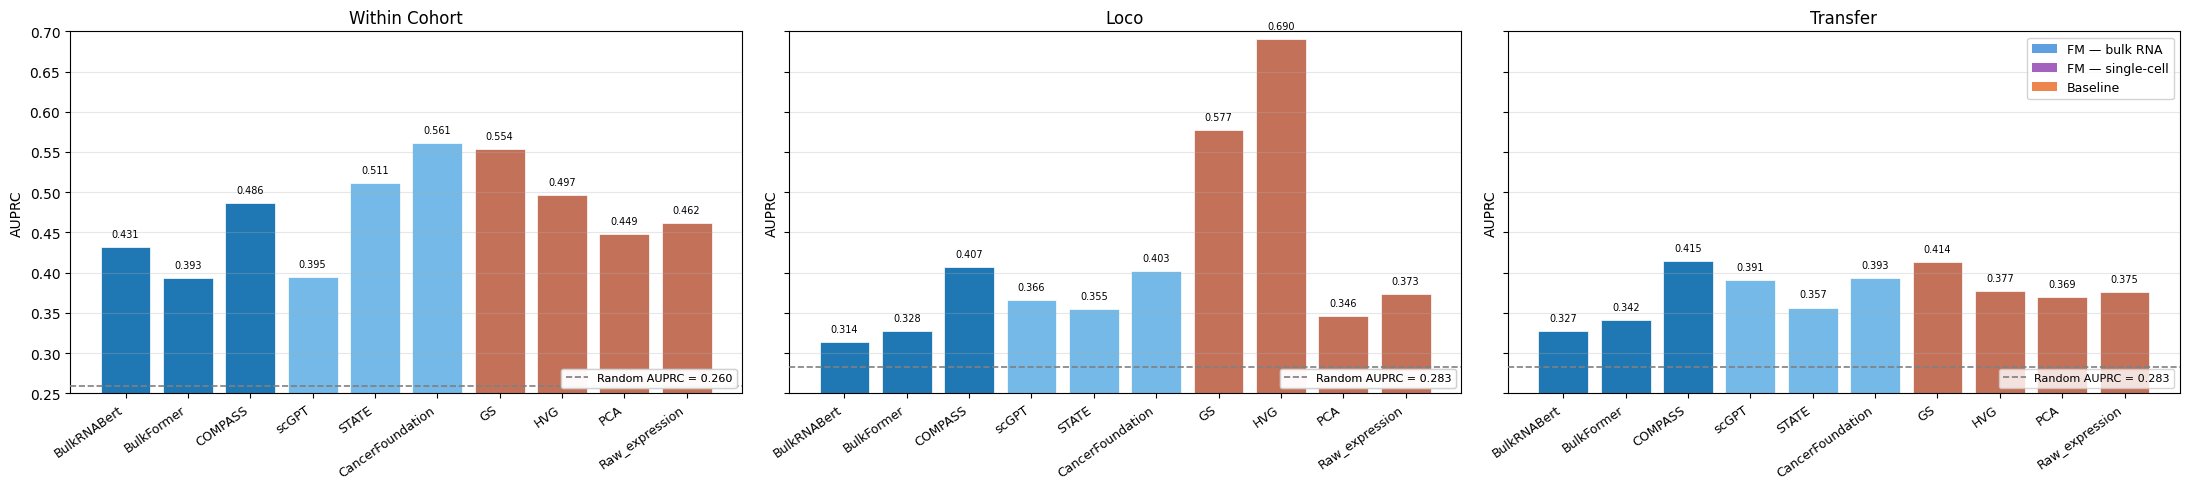

In [5]:
# Bar chart: best AUPRC per embedding category across paradigms
# FMs (blues/purples) are visually separated from baselines (oranges/neutrals)
# by a vertical dashed line and a legend.

from matplotlib.patches import Patch
from matplotlib.lines import Line2D

def plot_category_bar(paradigm, verbose=True, ax=None):
    df_agg = agg.get(paradigm)
    if df_agg is None or df_agg.empty:
        return
    summary = best_per_category(df_agg, verbose=verbose)
    if summary.empty:
        return
    cats   = summary['category'].tolist()
    means  = summary['overall_pr_auc_mean'].tolist()
    colors = [PALETTE.get(c, '#999999') for c in cats]

    if ax is None:
        fig, ax = plt.subplots(figsize=(max(6, len(cats) * 0.9), 4))

    x    = np.arange(len(cats))
    bars = ax.bar(x, means, color=colors, edgecolor='white', linewidth=0.5)

    rand_val = RANDOM_AUPRC.get(paradigm, np.nan)
    if not np.isnan(rand_val):
        ax.axhline(rand_val, color='gray', linestyle='--', linewidth=1.2, zorder=5)
        rand_handle = Line2D([0], [0], color='gray', linestyle='--', linewidth=1.2,
                             label=f'Random AUPRC = {rand_val:.3f}')
        rand_leg = ax.legend(handles=[rand_handle], loc='lower right', fontsize=8, framealpha=0.8)
        ax.add_artist(rand_leg)

    ax.set_xticks(x)
    ax.set_xticklabels(cats, rotation=35, ha='right', fontsize=9)
    ax.set_ylabel('AUPRC')
    ax.set_ylim(0.25, 0.70)
    ax.set_title(paradigm.replace('_', ' ').title())
    ax.grid(axis='y', alpha=0.3)
    for bar, m in zip(bars, means):
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01,
                f'{m:.3f}', ha='center', va='bottom', fontsize=7)


fig, axes = plt.subplots(1, 3, figsize=(22, 5), sharey=True)
for ax, p in zip(axes, ['within_cohort', 'loco', 'transfer']):
    plot_category_bar(p, verbose=True, ax=ax)

legend_elems = [
    Patch(facecolor='#1976D2', alpha=0.7, label='FM — bulk RNA'),
    Patch(facecolor='#7B1FA2', alpha=0.7, label='FM — single-cell'),
    Patch(facecolor='#E65100', alpha=0.7, label='Baseline'),
]
axes[-1].legend(handles=legend_elems, loc='upper right', fontsize=9, framealpha=0.85)

#plt.suptitle('ICI Response Prediction — Best AUPRC per Embedding Category', fontsize=13, y=1.02)
plt.tight_layout()
FIG_DIR = REPO_ROOT / 'benchmarking_results' / 'figures' / 'ICI'
FIG_DIR.mkdir(parents=True, exist_ok=True)
plt.savefig(FIG_DIR / 'ICI_auprc_by_category.png', bbox_inches='tight', dpi=150)
plt.show()

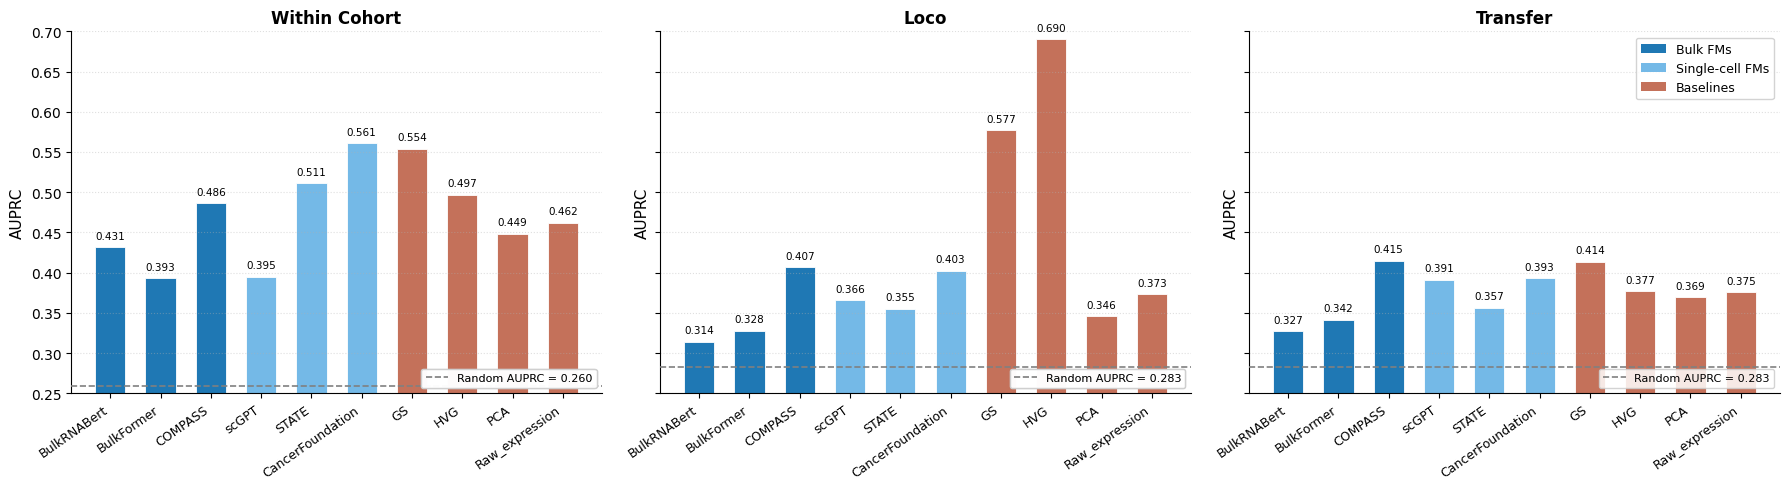

In [6]:
# import mpatches
import matplotlib.patches as mpatches

def plot_category_bar(paradigm, verbose=True, ax=None):
    df_agg = agg.get(paradigm)
    if df_agg is None or df_agg.empty:
        return
    summary = best_per_category(df_agg, verbose=verbose)
    if summary.empty:
        return
    cats   = summary['category'].tolist()
    means  = summary['overall_pr_auc_mean'].tolist()
    colors = [PALETTE.get(c, '#999999') for c in cats]

    if ax is None:
        fig, ax = plt.subplots(figsize=(max(6, len(cats) * 0.9), 4))

    x = np.arange(len(cats))
    bars = ax.bar(x, means, color=colors, edgecolor='white', linewidth=0.6, width=0.6)

    rand_val = RANDOM_AUPRC.get(paradigm, np.nan)
    if not np.isnan(rand_val):
        ax.axhline(rand_val, color='gray', linestyle='--', linewidth=1.2, zorder=5)
        rand_leg = ax.legend(
            handles=[Line2D([0], [0], color='gray', ls='--', lw=1.2,
                            label=f'Random AUPRC = {rand_val:.3f}')],
            loc='lower right', fontsize=8, framealpha=0.85)
        ax.add_artist(rand_leg)

    ax.set_xticks(x)
    ax.set_xticklabels(cats, rotation=35, ha='right', fontsize=9)
    ax.set_ylabel('AUPRC', fontsize=11)
    ax.set_ylim(0.25, 0.70)
    ax.set_title(paradigm.replace('_', ' ').title(), fontsize=12, fontweight='bold')
    ax.grid(axis='y', ls=':', alpha=0.4)
    ax.spines[['top', 'right']].set_visible(False)
    for bar, m in zip(bars, means):
        ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.008,
                f'{m:.3f}', ha='center', va='bottom', fontsize=7.5)


fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharey=True)
for ax, p in zip(axes, ['within_cohort', 'loco', 'transfer']):
    plot_category_bar(p, verbose=True, ax=ax)

axes[-1].legend(handles=[
    mpatches.Patch(facecolor='#1F78B4', label='Bulk FMs'),
    mpatches.Patch(facecolor='#74B9E7', label='Single-cell FMs'),
    mpatches.Patch(facecolor='#C4715A', label='Baselines'),
], loc='upper right', fontsize=9, framealpha=0.85)

#plt.suptitle('ICI Response Prediction — Best AUPRC per Embedding', fontsize=13,fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig(FIG_DIR / 'ICI_auprc_by_category.png', bbox_inches='tight', dpi=300)
plt.show()

In [7]:
# FM vs baseline summary table
rows = []
for p in ['within_cohort', 'loco', 'transfer']:
    df_agg = agg.get(p)
    if df_agg is None or df_agg.empty: continue
    for _, row in best_per_category(df_agg, verbose=False).iterrows():
        rows.append({'paradigm': p, 'category': row['category'],
                     'pr_auc_mean': row['overall_pr_auc_mean'],
                     'pr_auc_std':  row['overall_pr_auc_std'],
                     'RNA_key': row['RNA_key'], 'nHVGs': row['nHVGs']})
summary_df = pd.DataFrame(rows)
if not summary_df.empty:
    summary_df['value'] = summary_df.apply(
        lambda r: f"{r['pr_auc_mean']:.3f} +/- {r['pr_auc_std']:.3f}"
                  if pd.notna(r['pr_auc_std']) else f"{r['pr_auc_mean']:.3f}", axis=1)
    display(summary_df.pivot(index='category', columns='paradigm', values='value').reindex(CATEGORY_ORDER))


paradigm,loco,transfer,within_cohort
category,,,
FM_BULK,0.407 +/- 0.045,0.415 +/- 0.036,0.486 +/- 0.123
FM_SC,0.403 +/- 0.027,0.393 +/- 0.030,0.561 +/- 0.119
GS,0.577 +/- 0.050,0.414 +/- 0.034,0.554 +/- 0.076
HVG,0.690 +/- 0.069,0.377 +/- 0.047,0.497 +/- 0.098
PCA,0.346 +/- 0.036,0.369 +/- 0.045,0.449 +/- 0.099
Raw_expression,0.373 +/- 0.042,0.375 +/- 0.049,0.462 +/- 0.079


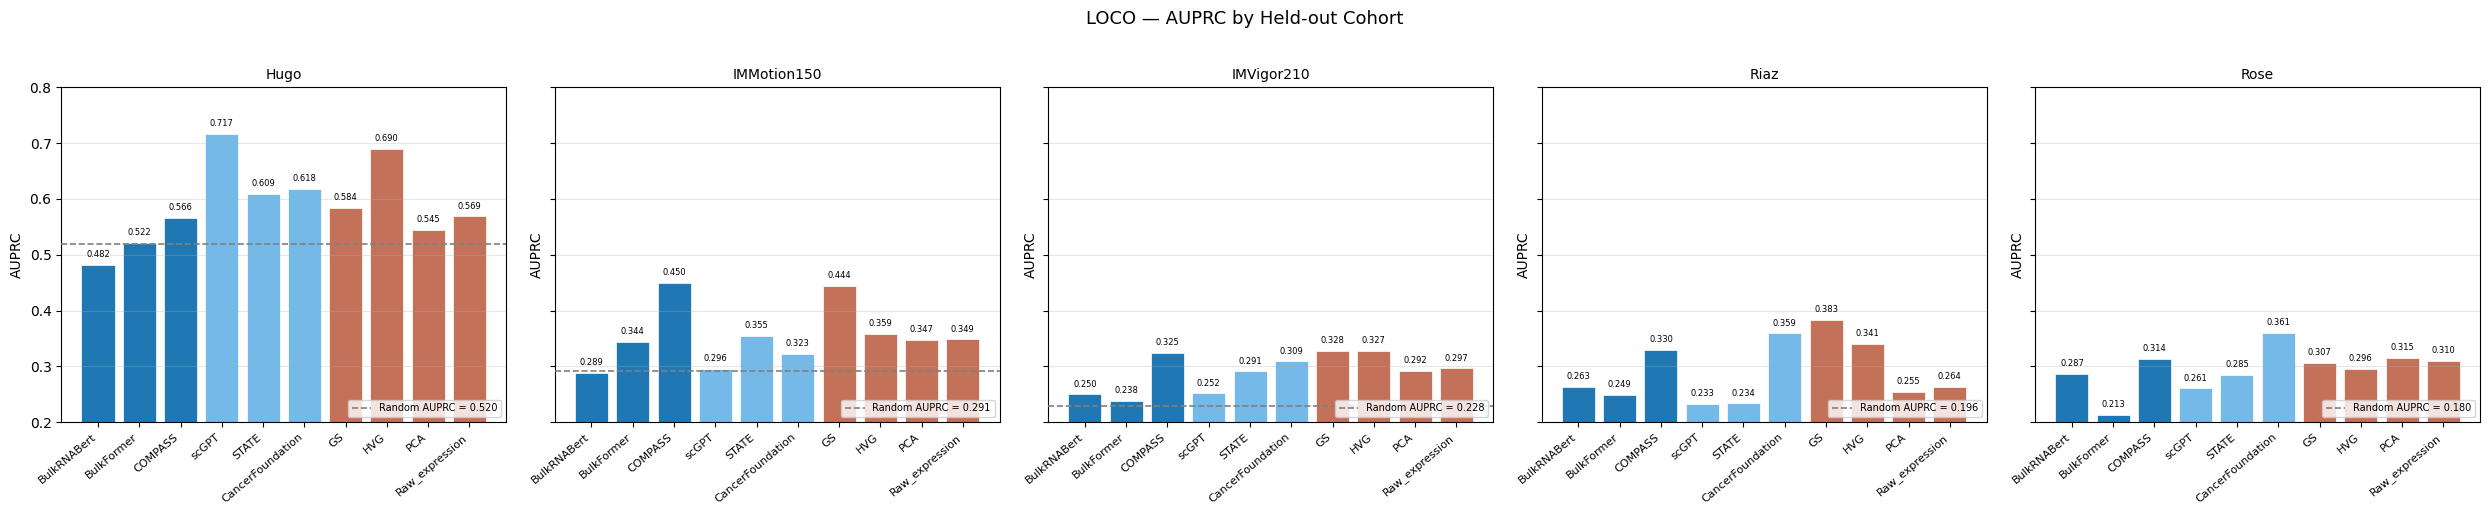

In [8]:
# LOCO: per held-out cohort bar charts
df_loco = agg.get('loco', pd.DataFrame())
if df_loco.empty:
    print('No LOCO data yet')
else:
    tags = sorted(df_loco['cohort_tag'].unique())
    fig, axes = plt.subplots(1, len(tags), figsize=(5*len(tags), 5), sharey=True)
    if len(tags) == 1: axes = [axes]
    for ax, tag in zip(axes, tags):
        sub = df_loco[df_loco['cohort_tag'] == tag]
        s   = best_per_category(sub, verbose=True)
        if s.empty: continue
        cats   = s['category'].tolist()
        means  = s['overall_pr_auc_mean'].tolist()
        colors = [PALETTE.get(c, '#999999') for c in cats]
        x    = np.arange(len(cats))
        bars = ax.bar(x, means, color=colors, edgecolor='white', linewidth=0.5)

        held_out = tag.replace('loco_held_out_', '')
        rand_val = pos_frac.get(held_out, np.nan)
        if not np.isnan(rand_val):
            ax.axhline(rand_val, color='gray', linestyle='--', linewidth=1.2, zorder=5)
            rand_handle = Line2D([0], [0], color='gray', linestyle='--', linewidth=1.2,
                                 label=f'Random AUPRC = {rand_val:.3f}')
            ax.legend(handles=[rand_handle], loc='lower right', fontsize=7, framealpha=0.8)

        ax.set_xticks(x)
        ax.set_xticklabels(cats, rotation=40, ha='right', fontsize=8)
        ax.set_title(held_out, fontsize=10)
        ax.set_ylabel('AUPRC')
        ax.set_ylim(0.2, 0.8)
        ax.grid(axis='y', alpha=0.3)
        for bar, m in zip(bars, means):
            ax.text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.01, f'{m:.3f}',
                    ha='center', va='bottom', fontsize=6)
    plt.suptitle('LOCO — AUPRC by Held-out Cohort', fontsize=13, y=1.02)
    plt.tight_layout()
    plt.savefig(FIG_DIR / 'ICI_loco_per_cohort.png', bbox_inches='tight', dpi=150)
    plt.show()

In [9]:
# LOCO per-cohort table
df_loco = agg['loco'].copy()
global_best = best_per_category(df_loco, verbose=False)[['category','RNA_key','nHVGs','arch']]
df_loco = df_loco.merge(global_best, on=['category','RNA_key','nHVGs','arch'])
pivot = df_loco.pivot_table(index='category', columns='cohort_tag',
                             values='overall_pr_auc_mean', aggfunc='mean')
pivot.columns = [c.replace('loco_held_out_', '') for c in pivot.columns]
pivot = pivot.reindex(CATEGORY_ORDER)
pivot['mean'] = pivot.mean(axis=1)
display(pivot.round(3).sort_values('mean', ascending=False))

,Hugo,IMMotion150,IMVigor210,Riaz,Rose,mean
category,,,,,,
HVG,0.690,NaN,NaN,NaN,NaN,0.690
GS,0.577,NaN,NaN,NaN,NaN,0.577
FM_BULK,0.566,NaN,0.325,0.330,NaN,0.407
FM_SC,0.618,0.323,0.309,NaN,0.361,0.403
Raw_expression,0.569,0.349,NaN,0.264,0.310,0.373
PCA,0.543,0.342,0.275,0.255,0.315,0.346


AUPRC per category by cancer type of held-out cohort:


cancer_type,BLCA,KIRC,SKCM,mean
category,,,,
HVG,NaN,NaN,0.690,0.690
GS,NaN,NaN,0.577,0.577
FM_SC,0.335,0.323,0.618,0.425
FM_BULK,0.325,NaN,0.448,0.386
Raw_expression,0.310,0.349,0.416,0.358
PCA,0.295,0.342,0.399,0.345


  SKCM: ['Hugo', 'Riaz']
  BLCA: ['Rose', 'IMVigor210']
  KIRC: ['IMMotion150']


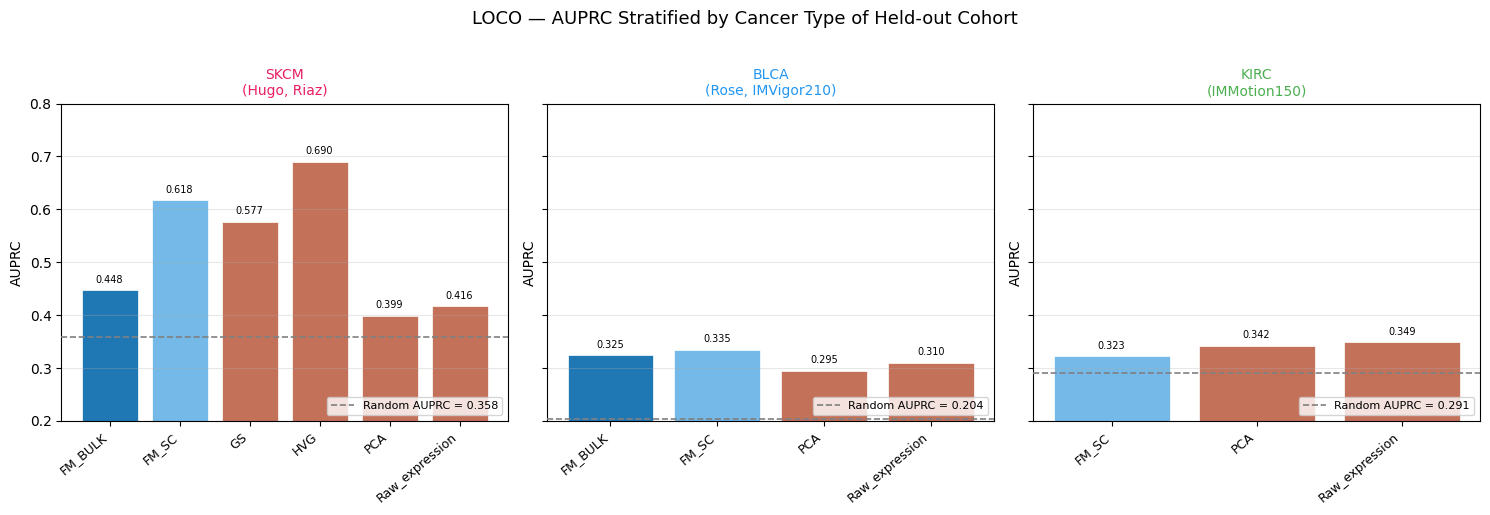

In [10]:
# LOCO stratified by cancer type of held-out cohort
df_loco = agg['loco'].copy()
global_best = best_per_category(df_loco, verbose=False)[['category','RNA_key','nHVGs','arch']]
df_loco = df_loco.merge(global_best, on=['category','RNA_key','nHVGs','arch'])
df_loco['held_out']    = df_loco['cohort_tag'].str.replace('loco_held_out_', '', regex=False)
df_loco['cancer_type'] = df_loco['held_out'].map(COHORT_CANCER_TYPE)

ct_summary = (
    df_loco.groupby(['cancer_type', 'category'])['overall_pr_auc_mean']
    .mean().reset_index()
    .pivot(index='category', columns='cancer_type', values='overall_pr_auc_mean')
    .reindex(CATEGORY_ORDER)
)
ct_summary['mean'] = ct_summary.mean(axis=1)
print("AUPRC per category by cancer type of held-out cohort:")
display(ct_summary.round(3).sort_values('mean', ascending=False))
for ct, cohorts in CANCER_TYPE_COHORTS.items():
    print(f"  {ct}: {cohorts}")

# Random AUPRC per cancer type = mean positive fraction of cohorts in that cancer type
cancer_type_rand = {
    ct: np.mean([pos_frac[c] for c in cohorts if c in pos_frac])
    for ct, cohorts in CANCER_TYPE_COHORTS.items()
}

cancer_types = ['SKCM', 'BLCA', 'KIRC']
fig, axes = plt.subplots(1, 3, figsize=(15, 5), sharey=True)
for ax, ct in zip(axes, cancer_types):
    cohorts_ct = CANCER_TYPE_COHORTS.get(ct, [])
    tags = [f'loco_held_out_{c}' for c in cohorts_ct]
    sub  = df_loco[df_loco['cohort_tag'].isin(tags)]
    if sub.empty:
        ax.set_title(ct); continue
    best_sub = (
        sub.groupby('category')['overall_pr_auc_mean']
        .agg(mean='mean', std='std').reset_index()
    )
    best_sub['category'] = pd.Categorical(best_sub['category'], categories=CATEGORY_ORDER, ordered=True)
    best_sub = best_sub.sort_values('category').dropna(subset=['mean'])
    cats   = best_sub['category'].tolist()
    means  = best_sub['mean'].tolist()
    colors = [PALETTE.get(c, '#999999') for c in cats]
    x    = np.arange(len(cats))
    bars = ax.bar(x, means, color=colors, edgecolor='white', linewidth=0.5)

    rand_val = cancer_type_rand.get(ct, np.nan)
    if not np.isnan(rand_val):
        ax.axhline(rand_val, color='gray', linestyle='--', linewidth=1.2, zorder=5)
        rand_handle = Line2D([0], [0], color='gray', linestyle='--', linewidth=1.2,
                             label=f'Random AUPRC = {rand_val:.3f}')
        ax.legend(handles=[rand_handle], loc='lower right', fontsize=8, framealpha=0.8)

    ax.set_xticks(x)
    ax.set_xticklabels(cats, rotation=40, ha='right', fontsize=9)
    ax.set_title(f'{ct}\n({", ".join(cohorts_ct)})', fontsize=10,
                 color=CANCER_TYPE_COLOR.get(ct, 'black'))
    ax.set_ylabel('AUPRC')
    ax.set_ylim(0.2, 0.8)
    ax.grid(axis='y', alpha=0.3)
    for bar, m in zip(bars, means):
        ax.text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.01, f'{m:.3f}',
                ha='center', va='bottom', fontsize=7)
plt.suptitle('LOCO — AUPRC Stratified by Cancer Type of Held-out Cohort', fontsize=13, y=1.02)
plt.tight_layout()
plt.savefig(FIG_DIR / 'ICI_loco_by_cancer_type.png', bbox_inches='tight', dpi=150)
plt.show()

AUPRC per category by cancer type of held-out cohort:


cancer_type,BLCA,KIRC,SKCM,mean
category,,,,
HVG,NaN,NaN,0.690,0.690
GS,NaN,NaN,0.577,0.577
FM_SC,0.335,0.323,0.618,0.425
FM_BULK,0.325,NaN,0.448,0.386
Raw_expression,0.310,0.349,0.416,0.358
PCA,0.295,0.342,0.399,0.345


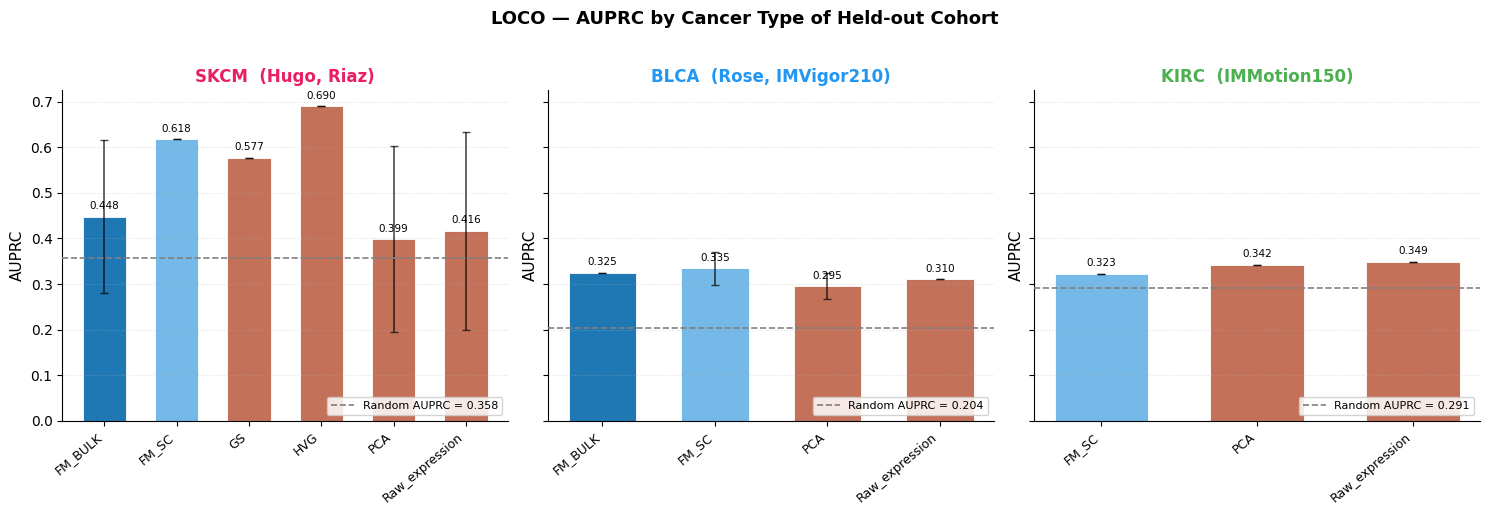

In [11]:
# LOCO stratified by cancer type of held-out cohort
df_loco = agg['loco'].copy()
global_best = best_per_category(df_loco, verbose=False)[['category', 'RNA_key', 'nHVGs', 'arch']]
df_loco = df_loco.merge(global_best, on=['category', 'RNA_key', 'nHVGs', 'arch'])
df_loco['held_out']    = df_loco['cohort_tag'].str.replace('loco_held_out_', '', regex=False)
df_loco['cancer_type'] = df_loco['held_out'].map(COHORT_CANCER_TYPE)

ct_summary = (
    df_loco.groupby(['cancer_type', 'category'])['overall_pr_auc_mean']
    .mean().reset_index()
    .pivot(index='category', columns='cancer_type', values='overall_pr_auc_mean')
    .reindex(CATEGORY_ORDER)
)
ct_summary['mean'] = ct_summary.mean(axis=1)
print("AUPRC per category by cancer type of held-out cohort:")
display(ct_summary.round(3).sort_values('mean', ascending=False))

cancer_type_rand = {
    ct: np.mean([pos_frac[c] for c in cohorts if c in pos_frac])
    for ct, cohorts in CANCER_TYPE_COHORTS.items()
}

cancer_types = ['SKCM', 'BLCA', 'KIRC']
fig, axes = plt.subplots(1, 3, figsize=(15, 5), sharey=True)

for ax, ct in zip(axes, cancer_types):
    cohorts_ct = CANCER_TYPE_COHORTS.get(ct, [])
    tags = [f'loco_held_out_{c}' for c in cohorts_ct]
    sub  = df_loco[df_loco['cohort_tag'].isin(tags)]
    if sub.empty:
        ax.set_title(ct); continue

    best_sub = (
        sub.groupby('category')['overall_pr_auc_mean']
        .agg(mean='mean', std='std').reset_index()
    )
    best_sub['category'] = pd.Categorical(best_sub['category'],
                                          categories=CATEGORY_ORDER, ordered=True)
    best_sub = best_sub.sort_values('category').dropna(subset=['mean'])
    cats   = best_sub['category'].tolist()
    means  = best_sub['mean'].tolist()
    stds   = best_sub['std'].fillna(0).tolist()
    colors = [PALETTE.get(c, '#999999') for c in cats]
    x      = np.arange(len(cats))

    bars = ax.bar(x, means, color=colors, edgecolor='white', linewidth=0.6, width=0.6,
                  yerr=stds, capsize=3, error_kw={'elinewidth': 1.2, 'alpha': 0.7})

    rand_val = cancer_type_rand.get(ct, np.nan)
    if not np.isnan(rand_val):
        ax.axhline(rand_val, color='gray', linestyle='--', linewidth=1.2, zorder=5)
        ax.legend(
            handles=[Line2D([0], [0], color='gray', ls='--', lw=1.2,
                            label=f'Random AUPRC = {rand_val:.3f}')],
            loc='lower right', fontsize=8, framealpha=0.85)

    ax.set_xticks(x)
    ax.set_xticklabels(cats, rotation=40, ha='right', fontsize=9)
    ax.set_title(f'{ct}  ({", ".join(cohorts_ct)})', fontsize=12, fontweight='bold',
                 color=CANCER_TYPE_COLOR.get(ct, 'black'))
    ax.set_ylabel('AUPRC', fontsize=11)
    ax.grid(axis='y', ls=':', alpha=0.4)
    ax.spines[['top', 'right']].set_visible(False)
    for bar, m in zip(bars, means):
        ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.012,
                f'{m:.3f}', ha='center', va='bottom', fontsize=7.5)

plt.suptitle('LOCO — AUPRC by Cancer Type of Held-out Cohort', fontsize=13,
             fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig(FIG_DIR / 'ICI_loco_by_cancer_type.png', bbox_inches='tight', dpi=300)
plt.show()


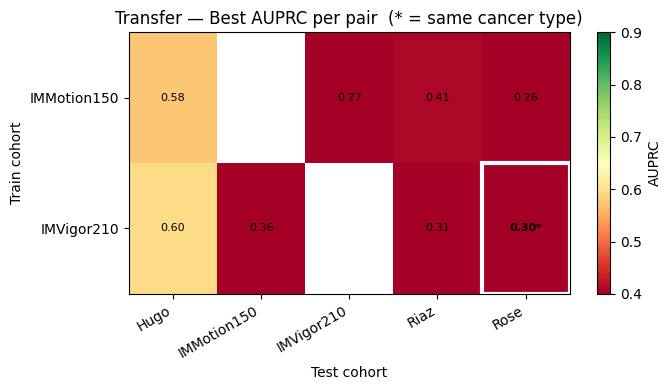


Same-cancer vs cross-cancer transfer:


,mean,std,count
type,,,
cross-cancer,0.397,0.139,7
same-cancer,0.296,NaN,1



Same-cancer pairs:


,train,test,cancer_type,auprc
7,IMVigor210,Rose,BLCA,0.296


In [12]:
# Transfer heatmap — same-cancer pairs marked with *
df_transfer = agg.get('transfer', pd.DataFrame())
if df_transfer.empty:
    print('No transfer data yet')
else:
    global_best = best_per_category(df_transfer, verbose=False)[['category','RNA_key','nHVGs','arch']]
    df_transfer_best = df_transfer.merge(global_best, on=['category','RNA_key','nHVGs','arch'])
    bpt = (df_transfer_best.groupby('cohort_tag')['overall_pr_auc_mean']
           .mean().reset_index())
    bpt['train'] = bpt['cohort_tag'].str.replace('transfer_', '').str.split('_to_').str[0]
    bpt['test']  = bpt['cohort_tag'].str.replace('transfer_', '').str.split('_to_').str[1]
    pivot = bpt.pivot(index='train', columns='test', values='overall_pr_auc_mean')

    fig, ax = plt.subplots(figsize=(7, 4))
    im = ax.imshow(pivot.values, vmin=0.4, vmax=0.9, cmap='RdYlGn', aspect='auto')
    ax.set_xticks(range(len(pivot.columns)))
    ax.set_yticks(range(len(pivot.index)))
    ax.set_xticklabels(pivot.columns, rotation=30, ha='right')
    ax.set_yticklabels(pivot.index)
    ax.set_xlabel('Test cohort')
    ax.set_ylabel('Train cohort')
    ax.set_title('Transfer — Best AUPRC per pair  (* = same cancer type)')
    plt.colorbar(im, ax=ax, label='AUPRC')
    for i, train in enumerate(pivot.index):
        for j, test in enumerate(pivot.columns):
            val    = pivot.values[i, j]
            is_sc  = (train, test) in SAME_CANCER_PAIRS
            if not np.isnan(val):
                ax.text(j, i, f'{val:.2f}{"*" if is_sc else ""}',
                        ha='center', va='center', fontsize=8,
                        fontweight='bold' if is_sc else 'normal')
            if is_sc:
                ax.add_patch(plt.Rectangle((j-0.5, i-0.5), 1, 1,
                             fill=False, edgecolor='white', linewidth=3))
    plt.tight_layout()
    plt.savefig(FIG_DIR / 'ICI_transfer_heatmap.png', bbox_inches='tight', dpi=150)
    plt.show()

    rows_sc = [{'train': r.train, 'test': r.test,
                'auprc': r.overall_pr_auc_mean,
                'type': 'same-cancer' if (r.train, r.test) in SAME_CANCER_PAIRS else 'cross-cancer',
                'cancer_type': COHORT_CANCER_TYPE.get(r.train, '?')}
               for r in bpt.itertuples()]
    df_sc = pd.DataFrame(rows_sc)
    print("\nSame-cancer vs cross-cancer transfer:")
    display(df_sc.groupby('type')['auprc'].agg(['mean','std','count']).round(3))
    print("\nSame-cancer pairs:")
    display(df_sc[df_sc['type']=='same-cancer'][['train','test','cancer_type','auprc']].round(3))


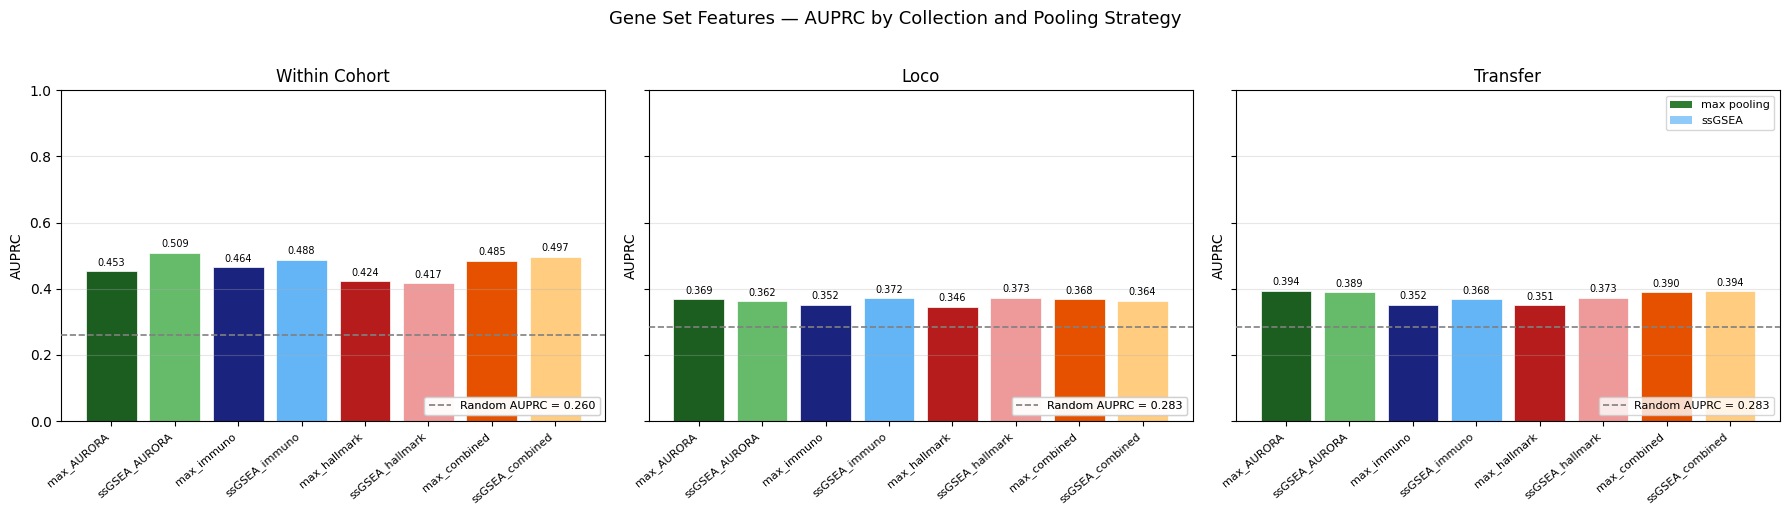

paradigm,within_cohort,loco,transfer,mean
RNA_key,,,,
ssGSEA_AURORA,0.509,0.362,0.389,0.420
ssGSEA_combined,0.497,0.364,0.394,0.418
max_combined,0.485,0.368,0.390,0.414
ssGSEA_immuno,0.488,0.372,0.368,0.410
max_AURORA,0.453,0.369,0.394,0.405
max_immuno,0.464,0.352,0.352,0.389
ssGSEA_hallmark,0.417,0.373,0.373,0.388
max_hallmark,0.424,0.346,0.351,0.373


In [13]:
# Gene set breakdown: max_* vs ssGSEA_* across collections
GS_ORDER = ['max_AURORA','ssGSEA_AURORA','max_immuno','ssGSEA_immuno',
            'max_hallmark','ssGSEA_hallmark','max_combined','ssGSEA_combined']
GS_PALETTE = {
    'max_AURORA':'#1B5E20', 'ssGSEA_AURORA':'#66BB6A',
    'max_immuno':'#1A237E', 'ssGSEA_immuno':'#64B5F6',
    'max_hallmark':'#B71C1C', 'ssGSEA_hallmark':'#EF9A9A',
    'max_combined':'#E65100', 'ssGSEA_combined':'#FFCC80',
}

gs_rows = []
for p in ['within_cohort', 'loco', 'transfer']:
    df_agg = agg.get(p, pd.DataFrame())
    if df_agg.empty: continue
    gs_df = df_agg[df_agg['RNA_key'].isin(GS_ORDER)].copy()
    if gs_df.empty: continue
    m = gs_df.groupby('RNA_key')['overall_pr_auc_mean'].mean().reset_index().rename(columns={'overall_pr_auc_mean':'pr_auc'})
    s = gs_df.groupby('RNA_key')['overall_pr_auc_mean'].std().reset_index().rename(columns={'overall_pr_auc_mean':'pr_auc_std'})
    merged = m.merge(s, on='RNA_key')
    merged['paradigm'] = p
    gs_rows.append(merged)

gs_summary = pd.concat(gs_rows, ignore_index=True) if gs_rows else pd.DataFrame()

if gs_summary.empty:
    print('No gene-set data yet')
else:
    paradigms = ['within_cohort', 'loco', 'transfer']
    fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharey=True)
    for ax, p in zip(axes, paradigms):
        sub = gs_summary[gs_summary['paradigm']==p].set_index('RNA_key').reindex(GS_ORDER).dropna().reset_index()
        if sub.empty: ax.set_title(p); continue
        x      = np.arange(len(sub))
        colors = [GS_PALETTE[k] for k in sub['RNA_key']]
        bars   = ax.bar(x, sub['pr_auc'],
                        capsize=4, color=colors, edgecolor='white', linewidth=0.5)

        rand_val = RANDOM_AUPRC.get(p, np.nan)
        if not np.isnan(rand_val):
            ax.axhline(rand_val, color='gray', linestyle='--', linewidth=1.2, zorder=5)
            rand_handle = Line2D([0], [0], color='gray', linestyle='--', linewidth=1.2,
                                 label=f'Random AUPRC = {rand_val:.3f}')
            rand_leg = ax.legend(handles=[rand_handle], loc='lower right', fontsize=8, framealpha=0.8)
            ax.add_artist(rand_leg)

        ax.set_xticks(x)
        ax.set_xticklabels(sub['RNA_key'], rotation=40, ha='right', fontsize=8)
        ax.set_title(p.replace('_',' ').title())
        ax.set_ylabel('AUPRC')
        ax.set_ylim(0, 1)
        ax.grid(axis='y', alpha=0.3)
        for bar, v in zip(bars, sub['pr_auc']):
            ax.text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.01, f'{v:.3f}',
                    ha='center', va='bottom', fontsize=7)
    from matplotlib.patches import Patch
    axes[-1].legend(handles=[Patch(facecolor='#2E7D32', label='max pooling'),
                              Patch(facecolor='#90CAF9', label='ssGSEA')], fontsize=8)
    plt.suptitle('Gene Set Features — AUPRC by Collection and Pooling Strategy', fontsize=13, y=1.02)
    plt.tight_layout()
    plt.savefig(FIG_DIR / 'ICI_gs_breakdown.png', bbox_inches='tight', dpi=150)
    plt.show()
    pivot_gs = gs_summary.pivot(index='RNA_key', columns='paradigm', values='pr_auc').reindex(GS_ORDER).reindex(columns=paradigms)
    pivot_gs['mean'] = pivot_gs.mean(axis=1)
    display(pivot_gs.round(3).sort_values('mean', ascending=False))

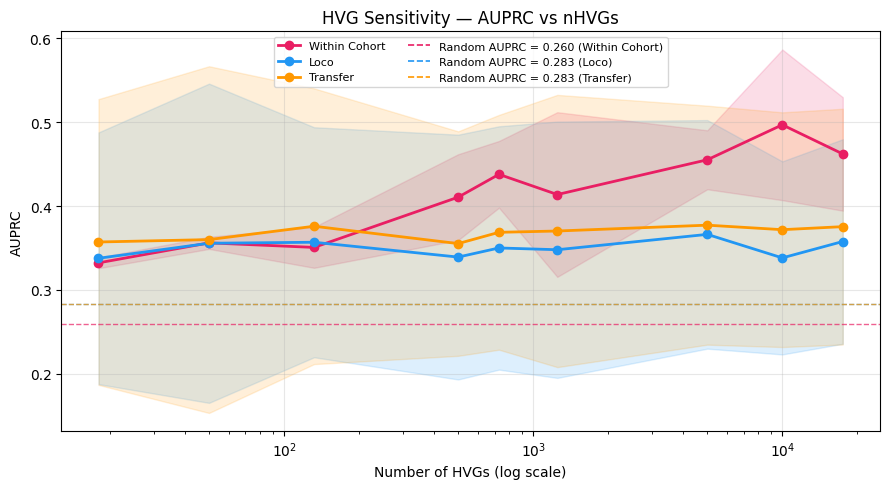

In [14]:
# HVG sensitivity
PARADIGM_COLORS = {'within_cohort':'#E91E63','loco':'#2196F3','transfer':'#FF9800'}

hvg_rows = []
for p in ['within_cohort', 'loco', 'transfer']:
    df_agg = agg.get(p, pd.DataFrame())
    if df_agg.empty: continue
    hvg_df = df_agg[(df_agg['RNA_key']=='RNA_seq') & (df_agg['nHVGs']!='None') & df_agg['nHVGs'].notna()].copy()
    if hvg_df.empty: continue
    hvg_df['nHVGs_int'] = hvg_df['nHVGs'].astype(float).astype(int)
    mean_df = hvg_df.groupby('nHVGs_int')['overall_pr_auc_mean'].agg(pr_auc='mean', pr_auc_std='std').reset_index()
    mean_df['paradigm'] = p
    hvg_rows.append(mean_df)

raw_rows = []
for p in ['within_cohort', 'loco', 'transfer']:
    df_agg = agg.get(p, pd.DataFrame())
    if df_agg.empty: continue
    raw_df = df_agg[(df_agg['RNA_key']=='RNA_seq') & (df_agg['nHVGs']=='None')].copy()
    if raw_df.empty: continue
    raw_rows.append({'paradigm':p,'nHVGs_int':17490,'pr_auc':raw_df['overall_pr_auc_mean'].mean(),'pr_auc_std':raw_df['overall_pr_auc_mean'].std()})

hvg_summary = pd.concat(hvg_rows + ([pd.DataFrame(raw_rows)] if raw_rows else []), ignore_index=True)

if hvg_summary.empty:
    print('No HVG data yet')
else:
    fig, ax = plt.subplots(figsize=(9, 5))
    rand_handles = []
    for p in ['within_cohort', 'loco', 'transfer']:
        sub   = hvg_summary[hvg_summary['paradigm']==p].sort_values('nHVGs_int')
        color = PARADIGM_COLORS[p]
        ax.plot(sub['nHVGs_int'], sub['pr_auc'], marker='o', label=p.replace('_',' ').title(),
                color=color, linewidth=2, markersize=6)
        ax.fill_between(sub['nHVGs_int'],
                        sub['pr_auc']-sub['pr_auc_std'].fillna(0),
                        sub['pr_auc']+sub['pr_auc_std'].fillna(0), alpha=0.15, color=color)
        rand_val = RANDOM_AUPRC.get(p, np.nan)
        if not np.isnan(rand_val):
            ax.axhline(rand_val, color=color, linestyle='--', linewidth=1.0, alpha=0.7)
            rand_handles.append(Line2D([0], [0], color=color, linestyle='--', linewidth=1.2,
                                       label=f'Random AUPRC = {rand_val:.3f} ({p.replace("_"," ").title()})'))
    ax.set_xscale('log')
    ax.set_xlabel('Number of HVGs (log scale)')
    ax.set_ylabel('AUPRC')
    ax.set_title('HVG Sensitivity — AUPRC vs nHVGs')
    solid_handles, solid_labels = ax.get_legend_handles_labels()
    ax.legend(handles=solid_handles + rand_handles, fontsize=8, ncol=2)
    ax.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.savefig(FIG_DIR / 'ICI_hvg_sensitivity.png', bbox_inches='tight', dpi=150)
    plt.show()

---
## COMPASS Fine-tuning Results (LFT / PFT / FFT)

In [15]:
COMPASS_FT_OUT   = MODEL_OUT / 'compass'
COMPASS_FT_MODES = ['LFT', 'PFT', 'FFT']


def load_compass_ft(paradigm, cohort_filter=None):
    base = COMPASS_FT_OUT / paradigm
    if not base.exists(): return pd.DataFrame()
    dfs = []
    for tag_dir in sorted(base.iterdir()):
        if not tag_dir.is_dir(): continue
        if cohort_filter and tag_dir.name not in cohort_filter: continue
        csv = tag_dir / 'all_metrics.csv'
        if csv.exists(): dfs.append(pd.read_csv(csv))
    return pd.concat(dfs, ignore_index=True) if dfs else pd.DataFrame()


def aggregate_compass_ft(paradigm, cohort_filter=None):
    df = load_compass_ft(paradigm, cohort_filter)
    if df.empty or 'overall_pr_auc' not in df.columns: return pd.DataFrame()
    df = df[df['error'].fillna('') == '']
    if 'val_pr_auc' in df.columns:
        val_mean = (
            df.dropna(subset=['val_pr_auc'])
            .groupby(['cohort_tag','mode'])['val_pr_auc'].mean().reset_index()
        )
        best_mode = (
            val_mean.sort_values('val_pr_auc', ascending=False)
            .groupby('cohort_tag', as_index=False).head(1)[['cohort_tag','mode']]
        )
        df = df.merge(best_mode, on=['cohort_tag','mode'])
    return (
        df.dropna(subset=['overall_pr_auc'])
        .groupby(['cohort_tag','mode'])['overall_pr_auc']
        .agg(pr_auc_mean='mean', pr_auc_std='std', n='count').reset_index()
    )


def aggregate_compass_ft_by_mode(paradigm, cohort_filter=None):
    df = load_compass_ft(paradigm, cohort_filter)
    if df.empty or 'overall_pr_auc' not in df.columns: return pd.DataFrame()
    df = df[df['error'].fillna('') == '']
    return (
        df.dropna(subset=['overall_pr_auc'])
        .groupby('mode')['overall_pr_auc']
        .agg(pr_auc_mean='mean', pr_auc_std='std', n='count').reset_index()
        .sort_values('mode')
    )


transfer_tags = [f'{s}_to_{t}' for s in TRANSFER_TRAIN_COHORTS for t in ALL_COHORTS if t != s]

cft = {
    'within_cohort': aggregate_compass_ft('within_cohort', WITHIN_COHORTS),
    'loco':          aggregate_compass_ft('loco'),
    'transfer':      aggregate_compass_ft('transfer', transfer_tags),
}
for p, df in cft.items():
    print(f"{p}: {len(df)} rows, modes={df['mode'].unique().tolist()}" if not df.empty else f"{p}: no data")

cft_by_mode = {
    'within_cohort': aggregate_compass_ft_by_mode('within_cohort', WITHIN_COHORTS),
    'loco':          aggregate_compass_ft_by_mode('loco'),
    'transfer':      aggregate_compass_ft_by_mode('transfer', transfer_tags),
}
for p, df in cft_by_mode.items():
    if not df.empty:
        print(f"\n{p} (all modes):")
        print(df[['mode','pr_auc_mean','pr_auc_std','n']].to_string(index=False))


within_cohort: 2 rows, modes=['LFT']
loco: 5 rows, modes=['LFT', 'PFT']
transfer: 8 rows, modes=['LFT', 'PFT']

within_cohort (all modes):
mode  pr_auc_mean  pr_auc_std  n
 FFT     0.353330    0.094569 10
 LFT     0.361556    0.093686 10
 PFT     0.354592    0.092120 10

loco (all modes):
mode  pr_auc_mean  pr_auc_std  n
 FFT     0.345704    0.151480 25
 LFT     0.412126    0.153300 25
 PFT     0.408893    0.124371 25

transfer (all modes):
mode  pr_auc_mean  pr_auc_std  n
 FFT     0.353928    0.147177 40
 LFT     0.369293    0.148355 40
 PFT     0.367520    0.144206 40


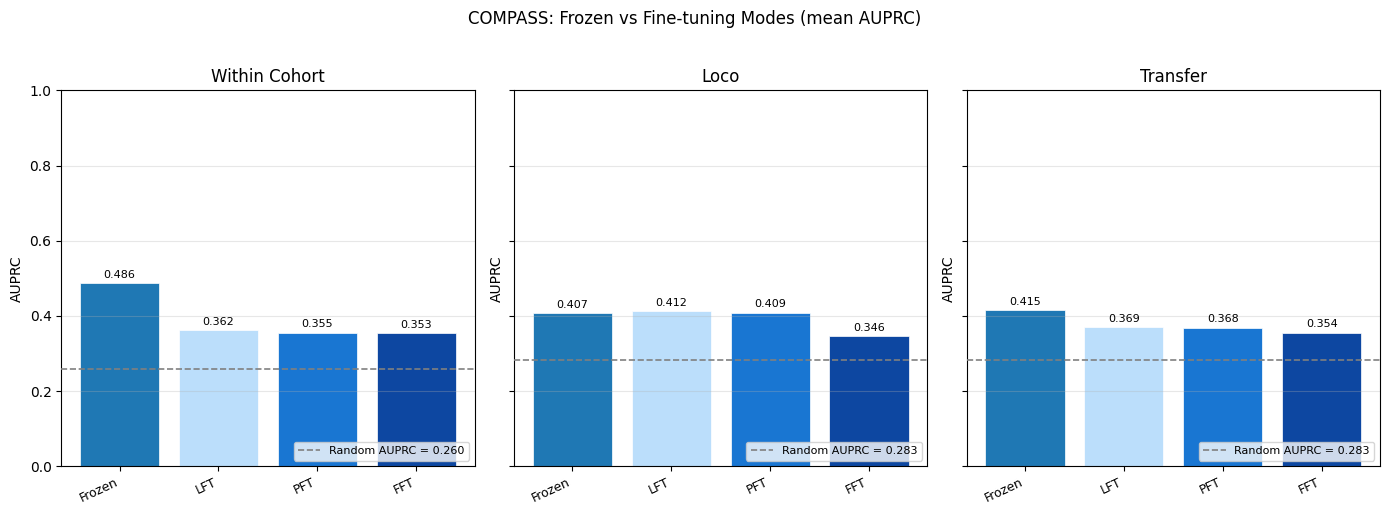

In [16]:
# COMPASS frozen vs FT modes bar chart
MODE_PALETTE = {'LFT':'#BBDEFB','PFT':'#1976D2','FFT':'#0D47A1'}
FROZEN_COLOR = PALETTE['COMPASS']


def plot_compass_ft_bar(paradigm, ax=None):
    df_agg_p = agg.get(paradigm, pd.DataFrame())
    frozen_mean, frozen_std = np.nan, np.nan
    if not df_agg_p.empty:
        cr = df_agg_p[df_agg_p['RNA_key']=='COMPASS']
        if not cr.empty:
            best_combo = cr.groupby(['nHVGs', 'arch'])['overall_pr_auc_mean'].mean().idxmax()
            mask = (cr['nHVGs'] == best_combo[0]) & (cr['arch'] == best_combo[1])
            frozen_mean = cr.loc[mask, 'overall_pr_auc_mean'].mean()
            frozen_std  = cr.loc[mask, 'overall_pr_auc_std'].mean()
    mode_stats = {}
    df_mode = cft_by_mode.get(paradigm, pd.DataFrame())
    if not df_mode.empty:
        mode_stats = df_mode.set_index('mode').reindex(COMPASS_FT_MODES).dropna().to_dict('index')
    labels = ['Frozen'] + list(mode_stats.keys())
    means  = [frozen_mean] + [mode_stats[m]['pr_auc_mean'] for m in mode_stats]
    colors = [FROZEN_COLOR]+ [MODE_PALETTE[m] for m in mode_stats]
    if ax is None:
        fig, ax = plt.subplots(figsize=(5, 4))
    x = np.arange(len(labels))
    ax.bar(x, means, color=colors, edgecolor='white', linewidth=0.5)

    rand_val = RANDOM_AUPRC.get(paradigm, np.nan)
    if not np.isnan(rand_val):
        ax.axhline(rand_val, color='gray', linestyle='--', linewidth=1.2, zorder=5)
        rand_handle = Line2D([0], [0], color='gray', linestyle='--', linewidth=1.2,
                             label=f'Random AUPRC = {rand_val:.3f}')
        ax.legend(handles=[rand_handle], loc='lower right', fontsize=8, framealpha=0.8)

    ax.set_xticks(x)
    ax.set_xticklabels(labels, rotation=25, ha='right', fontsize=9)
    ax.set_ylabel('AUPRC')
    ax.set_ylim(0, 1)
    ax.set_title(paradigm.replace('_',' ').title())
    ax.grid(axis='y', alpha=0.3)
    for xi, m in enumerate(means):
        if not np.isnan(m):
            ax.text(xi, m + 0.01, f'{m:.3f}', ha='center', va='bottom', fontsize=8)


fig, axes = plt.subplots(1, 3, figsize=(14, 5), sharey=True)
for ax, p in zip(axes, ['within_cohort','loco','transfer']):
    plot_compass_ft_bar(p, ax=ax)
plt.suptitle('COMPASS: Frozen vs Fine-tuning Modes (mean AUPRC)', fontsize=12, y=1.02)
plt.tight_layout()
plt.savefig(FIG_DIR / 'ICI_compass_ft_bar.png', bbox_inches='tight', dpi=150)
plt.show()

In [17]:
# COMPASS FT summary table
rows = []
for p in ['within_cohort', 'loco', 'transfer']:
    df_agg_p = agg.get(p, pd.DataFrame())
    if not df_agg_p.empty:
        cr = df_agg_p[df_agg_p['RNA_key']=='COMPASS']
        if not cr.empty:
            best_combo = cr.groupby(['nHVGs', 'arch'])['overall_pr_auc_mean'].mean().idxmax()
            mask = (cr['nHVGs'] == best_combo[0]) & (cr['arch'] == best_combo[1])
            rows.append({'paradigm':p,'model':'COMPASS (frozen)',
                         'pr_auc_mean':cr.loc[mask,'overall_pr_auc_mean'].mean(),
                         'pr_auc_std': cr.loc[mask,'overall_pr_auc_std'].mean()})
    df_mode_p = cft_by_mode.get(p, pd.DataFrame())
    if not df_mode_p.empty:
        for _, mrow in df_mode_p.iterrows():
            rows.append({'paradigm':p,'model':f'COMPASS-{mrow["mode"]}',
                         'pr_auc_mean':mrow['pr_auc_mean'],'pr_auc_std':mrow['pr_auc_std']})

summary = pd.DataFrame(rows)
if not summary.empty:
    summary['value'] = summary.apply(
        lambda r: f"{r['pr_auc_mean']:.3f} +/- {r['pr_auc_std']:.3f}"
                  if pd.notna(r['pr_auc_std']) else f"{r['pr_auc_mean']:.3f}", axis=1)
    pivot = summary.pivot(index='model', columns='paradigm', values='value')
    pivot = pivot.reindex([m for m in ['COMPASS (frozen)','COMPASS-LFT','COMPASS-PFT','COMPASS-FFT'] if m in pivot.index])
    pivot.columns.name = None
    display(pivot)

,loco,transfer,within_cohort
model,,,
COMPASS (frozen),0.407 +/- 0.045,0.415 +/- 0.036,0.486 +/- 0.123
COMPASS-LFT,0.412 +/- 0.153,0.369 +/- 0.148,0.362 +/- 0.094
COMPASS-PFT,0.409 +/- 0.124,0.368 +/- 0.144,0.355 +/- 0.092
COMPASS-FFT,0.346 +/- 0.151,0.354 +/- 0.147,0.353 +/- 0.095


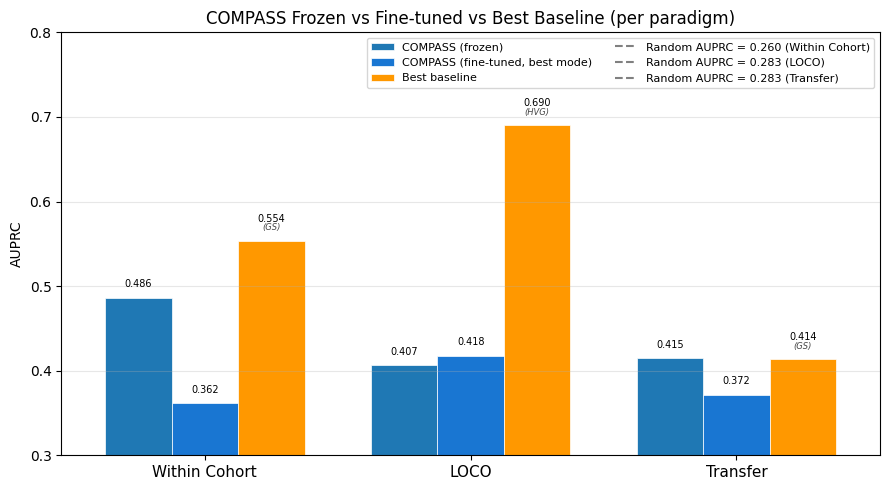


Best baseline per paradigm:
  within_cohort: GS = 0.554  (frozen COMPASS: 0.486, FT COMPASS: 0.362)
  loco: HVG = 0.690  (frozen COMPASS: 0.407, FT COMPASS: 0.418)
  transfer: GS = 0.414  (frozen COMPASS: 0.415, FT COMPASS: 0.372)


In [18]:
# 3-way comparison: frozen COMPASS vs best FT COMPASS vs best baseline (per paradigm)
BASELINE_CATS = {'GS', 'HVG', 'PCA', 'Raw_expression'}
rows = []
for p in ['within_cohort', 'loco', 'transfer']:
    df_agg_p = agg.get(p, pd.DataFrame())
    df_ft_p  = cft.get(p, pd.DataFrame())
    if df_agg_p.empty: continue
    cr = df_agg_p[df_agg_p['RNA_key'] == 'COMPASS']
    if not cr.empty:
        best_combo = cr.groupby(['nHVGs', 'arch'])['overall_pr_auc_mean'].mean().idxmax()
        mask = (cr['nHVGs'] == best_combo[0]) & (cr['arch'] == best_combo[1])
        frozen_mean = cr.loc[mask, 'overall_pr_auc_mean'].mean()
    else:
        frozen_mean = np.nan
    ft_mean = df_ft_p['pr_auc_mean'].mean() if not df_ft_p.empty else np.nan
    bl_df = df_agg_p[df_agg_p['category'].isin(BASELINE_CATS)]
    best_cat, bl_mean = '', np.nan
    if not bl_df.empty:
        combo_means = (bl_df.groupby(['category', 'RNA_key', 'nHVGs', 'arch'])['overall_pr_auc_mean']
                       .mean().reset_index()
                       .sort_values('overall_pr_auc_mean', ascending=False))
        best_row = combo_means.iloc[0]
        best_cat = best_row['category']
        bl_mean  = bl_df[
            (bl_df['RNA_key'] == best_row['RNA_key']) &
            (bl_df['nHVGs']   == best_row['nHVGs'])   &
            (bl_df['arch']    == best_row['arch'])
        ]['overall_pr_auc_mean'].mean()
    rows.append({'paradigm': p, 'frozen_mean': frozen_mean, 'ft_mean': ft_mean,
                 'bl_mean': bl_mean, 'best_cat': best_cat})

df_cmp = pd.DataFrame(rows)
if df_cmp.empty:
    print('No data yet')
else:
    plabels = {'within_cohort': 'Within Cohort', 'loco': 'LOCO', 'transfer': 'Transfer'}
    x, w = np.arange(len(df_cmp)), 0.25
    fig, ax = plt.subplots(figsize=(9, 5))
    b1 = ax.bar(x - w, df_cmp['frozen_mean'], w, color=PALETTE['COMPASS'],
                edgecolor='white', linewidth=0.5, label='COMPASS (frozen)')
    b2 = ax.bar(x,     df_cmp['ft_mean'],     w, color='#1976D2',
                edgecolor='white', linewidth=0.5, label='COMPASS (fine-tuned, best mode)')
    b3 = ax.bar(x + w, df_cmp['bl_mean'],     w, color='#FF9800',
                edgecolor='white', linewidth=0.5, label='Best baseline')
    for bars, col in [(b1, 'frozen_mean'), (b2, 'ft_mean')]:
        for bar, v in zip(bars, df_cmp[col]):
            if not np.isnan(v):
                ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01,
                        f'{v:.3f}', ha='center', va='bottom', fontsize=7)
    for i, row in df_cmp.iterrows():
        if not np.isnan(row['bl_mean']):
            ax.text(x[i] + w, row['bl_mean'] + 0.02, f'{row["bl_mean"]:.3f}',
                    ha='center', va='bottom', fontsize=7)
            ax.text(x[i] + w, row['bl_mean'] + 0.01, f'({row["best_cat"]})',
                    ha='center', va='bottom', fontsize=6, color='#444444', style='italic')

    # Per-paradigm random AUPRC: short horizontal segment spanning each group
    rand_handles = []
    for i, row in df_cmp.iterrows():
        rand_val = RANDOM_AUPRC.get(row['paradigm'], np.nan)
        if not np.isnan(rand_val):
            ax.hlines(rand_val, x[i] - w*1.6, x[i] + w*1.6,
                      colors='gray', linestyles='--', linewidth=1.5, zorder=5)
            rand_handles.append(Line2D([0], [0], color='gray', linestyle='--', linewidth=1.5,
                                       label=f'Random AUPRC = {rand_val:.3f} ({plabels[row["paradigm"]]})'))

    ax.set_xticks(x)
    ax.set_xticklabels([plabels[p] for p in df_cmp['paradigm']], fontsize=11)
    ax.set_ylabel('AUPRC')
    ax.set_ylim(0.3, 0.8)
    ax.set_title('COMPASS Frozen vs Fine-tuned vs Best Baseline (per paradigm)')
    bar_handles, bar_labels = ax.get_legend_handles_labels()
    ax.legend(handles=bar_handles + rand_handles, fontsize=8, ncol=2)
    ax.grid(axis='y', alpha=0.3)
    plt.tight_layout()
    plt.savefig(FIG_DIR / 'ICI_compass_comparison.png', bbox_inches='tight', dpi=150)
    plt.show()
    print("\nBest baseline per paradigm:")
    for _, row in df_cmp.iterrows():
        print(f"  {row['paradigm']}: {row['best_cat']} = {row['bl_mean']:.3f}  "
              f"(frozen COMPASS: {row['frozen_mean']:.3f}, FT COMPASS: {row['ft_mean']:.3f})")

### Save results

In [19]:
# ── Per-task best AUPRC (one row per cohort_tag × category) ───────────────────
rows = []
for paradigm, df_agg in agg.items():
    if df_agg is None or df_agg.empty:
        continue
    for tag in sorted(df_agg['cohort_tag'].unique()):
        sub = df_agg[df_agg['cohort_tag'] == tag].copy()
        # best model config per category for this specific experiment
        idx  = sub.groupby('category')['overall_pr_auc_mean'].idxmax().dropna()
        best = sub.loc[idx].copy()
        best['paradigm'] = paradigm
        rows.append(best)

df_per_task = pd.concat(rows, ignore_index=True)

# parse cohort_tag into readable columns
df_per_task['held_out']    = df_per_task['cohort_tag'].str.extract(r'loco_held_out_(.+)')
df_per_task['train_cohort'] = df_per_task['cohort_tag'].str.extract(r'transfer_(.+)_to_.+')
df_per_task['test_cohort']  = df_per_task['cohort_tag'].str.extract(r'transfer_.+_to_(.+)')
df_per_task['within_cohort_id'] = df_per_task['cohort_tag'].str.extract(r'within_cohort_(.+)')

keep = ['paradigm', 'cohort_tag', 'within_cohort_id', 'held_out',
        'train_cohort', 'test_cohort', 'category', 'RNA_key', 'nHVGs',
        'arch', 'loss', 'overall_pr_auc_mean', 'overall_pr_auc_std']
keep = [c for c in keep if c in df_per_task.columns]
df_per_task = df_per_task[keep].sort_values(['paradigm', 'cohort_tag', 'category']).reset_index(drop=True)

out_path = REPO_ROOT / 'benchmarking_results' / 'ICI' / 'per_task_best_auprc.csv'
out_path.parent.mkdir(parents=True, exist_ok=True)
df_per_task.to_csv(out_path, index=False)
print(f"Saved {len(df_per_task)} rows → {out_path}")
display(df_per_task)

Saved 90 rows → /data/rbg/users/ashyamal/RNA-FM-benchmarking/benchmarking_results/ICI/per_task_best_auprc.csv


,paradigm,cohort_tag,within_cohort_id,held_out,train_cohort,test_cohort,category,RNA_key,nHVGs,arch,overall_pr_auc_mean,overall_pr_auc_std
0,loco,loco_held_out_Hugo,NaN,Hugo,NaN,NaN,FM_BULK,COMPASS,None,ResidualMLP,0.565826,0.021655
1,loco,loco_held_out_Hugo,NaN,Hugo,NaN,NaN,FM_SC,scGPT,None,ResidualMLP,0.716596,0.049906
2,loco,loco_held_out_Hugo,NaN,Hugo,NaN,NaN,GS,ssGSEA_hallmark,None,Linear,0.584179,0.072650
3,loco,loco_held_out_Hugo,NaN,Hugo,NaN,NaN,HVG,RNA_seq,50.0,ResidualMLP,0.690121,0.069484
4,loco,loco_held_out_Hugo,NaN,Hugo,NaN,NaN,PCA,PCA_50,None,ResidualMLP,0.545200,0.029811
...,...,...,...,...,...,...,...,...,...,...,...,...
85,within_cohort,within_IMVigor210,NaN,NaN,NaN,NaN,FM_SC,CancerFoundation,None,Linear,0.561145,0.119331
86,within_cohort,within_IMVigor210,NaN,NaN,NaN,NaN,GS,max_AURORA,None,ResidualMLP,0.465612,0.126542
87,within_cohort,within_IMVigor210,NaN,NaN,NaN,NaN,HVG,RNA_seq,10000.0,ResidualMLP,0.560543,0.122981
88,within_cohort,within_IMVigor210,NaN,NaN,NaN,NaN,PCA,PCA_50,None,ResidualMLP,0.467396,0.081887
